#### Pivot Table-:
1. The pivot table takes simple column-wise data as input, and groups the entries into a two-dimensional table that provides a multidimensional summarization of the data.
2. It's help to reshape data from a long format to a wide format.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
df = sns.load_dataset('tips')
print(df.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [3]:
# Normal Method
print(df.groupby('sex')[['total_bill']].mean())
print(df.groupby(['sex','smoker'])[['total_bill']].mean().unstack())

        total_bill
sex               
Male     20.744076
Female   18.056897
       total_bill           
smoker        Yes         No
sex                         
Male    22.284500  19.791237
Female  17.977879  18.105185


In [4]:
# Pivot Table Method -: It's Also give same output as normal method.
print(df.pivot_table(index='sex',columns='smoker',values='total_bill'))

smoker        Yes         No
sex                         
Male    22.284500  19.791237
Female  17.977879  18.105185



#### 1. Aggregate in Pivot table-:
1. The aggfunc parameter controls the aggregate function inside pivot_table() like ('sum','mean','count','min','max','median','std').
2. By default, pivot_table() calculates the 'mean' (average) of the duplicates values.

In [5]:
print(df.pivot_table(index='sex',columns='smoker',values='total_bill'))  # By default mean
print(df.pivot_table(index='sex',columns='smoker',values='total_bill',aggfunc='std'))
print(df.pivot_table(index='sex',columns='smoker',values='total_bill',aggfunc='sum'))

smoker        Yes         No
sex                         
Male    22.284500  19.791237
Female  17.977879  18.105185
smoker       Yes        No
sex                       
Male    9.911845  8.726566
Female  9.189751  7.286455
smoker      Yes       No
sex                     
Male    1337.07  1919.75
Female   593.27   977.68


#### 2. All columns together-:
1. If you want to calculate all columns together.
2. You don't need to add values it's calculate on all the values.

In [11]:
print(df.pivot_table(index='sex',columns='smoker',aggfunc='count'))
print(df.pivot_table(index='sex',columns='smoker',aggfunc='count')['size'])  # Extract size only

       day     size     time     tip     total_bill    
smoker Yes  No  Yes  No  Yes  No Yes  No        Yes  No
sex                                                    
Male    60  97   60  97   60  97  60  97         60  97
Female  33  54   33  54   33  54  33  54         33  54
smoker  Yes  No
sex            
Male     60  97
Female   33  54


#### 3. Multidimensional-:
1. You can apply pivot_table on multiple columns.
2. If margins = true so It's calculate total values of all columns and rows.

In [13]:
df.pivot_table(index=['sex','smoker'],columns=['day','time'],aggfunc={'size':'mean','tip':'max','total_bill':'sum'})

size                                               tip  \
day                Thur              Fri              Sat       Sun  Thur   
time              Lunch Dinner     Lunch Dinner    Dinner    Dinner Lunch   
sex    smoker                                                               
Male   Yes     2.300000    NaN  1.666667    2.4  2.629630  2.600000  5.00   
       No      2.500000    NaN       NaN    2.0  2.656250  2.883721  6.70   
Female Yes     2.428571    NaN  2.000000    2.0  2.200000  2.500000  5.00   
       No      2.500000    2.0  3.000000    2.0  2.307692  3.071429  5.17   

                                                total_bill                \
day                    Fri           Sat    Sun       Thur           Fri   
time          Dinner Lunch Dinner Dinner Dinner      Lunch Dinner  Lunch   
sex    smoker                                                              
Male   Yes       NaN  2.20   4.73  10.00    6.5     191.71    NaN  34.16   
       No        NaN   NaN   3.50   9.00    6.0     369.73    NaN    NaN   
Female Yes       NaN  3.48   4.30   6.50    4.0     134.53    NaN  39.78   
       No        3.0  3.00   3.25   4.67    5.2     381.58  18.78  15.98   

                                       
day                       Sat     Sun  
time           Dinner  Dinner  Dinner  
sex    smoker                          
Male   Yes     129.46  589.62  392.12  
       No       34.95  637.73  877.34  
Female Yes      48.80  304.00   66.16  
       No       22.75  247.05  291.54

In [15]:
# Margins -: It's calculate total values of all columns and rows.
df.pivot_table(index='sex',columns='smoker',values='total_bill',aggfunc='sum',margins=True)

smoker,Yes,No,All
sex,,,
Male,1337.07,1919.75,3256.82
Female,593.27,977.68,1570.95
All,1930.34,2897.43,4827.77


In [16]:
df.pivot_table(index=['sex','smoker'],columns=['day','time'],aggfunc={'size':'mean','tip':'max','total_bill':'sum'},margins=True)

size                                                 \
day                Thur              Fri                 Sat       Sun   
time              Lunch Dinner     Lunch    Dinner    Dinner    Dinner   
sex    smoker                                                            
Male   Yes     2.300000    NaN  1.666667  2.400000  2.629630  2.600000   
       No      2.500000    NaN       NaN  2.000000  2.656250  2.883721   
Female Yes     2.428571    NaN  2.000000  2.000000  2.200000  2.500000   
       No      2.500000    2.0  3.000000  2.000000  2.307692  3.071429   
All            2.459016    2.0  2.000000  2.166667  2.517241  2.842105   

                          tip               ...                      \
day                 All  Thur          Fri  ...    Sat    Sun   All   
time                    Lunch Dinner Lunch  ... Dinner Dinner         
sex    smoker                               ...                       
Male   Yes     2.500000  5.00    NaN  2.20  ...  10.00    6.5  10.0   
       No      2.711340  6.70    NaN   NaN  ...   9.00    6.0   9.0   
Female Yes     2.242424  5.00    NaN  3.48  ...   6.50    4.0   6.5   
       No      2.592593  5.17    3.0  3.00  ...   4.67    5.2   5.2   
All            2.569672  6.70    3.0  3.48  ...  10.00    6.5  10.0   

              total_bill                                                   
day                 Thur           Fri              Sat      Sun      All  
time               Lunch Dinner  Lunch  Dinner   Dinner   Dinner           
sex    smoker                                                              
Male   Yes        191.71    NaN  34.16  129.46   589.62   392.12  1337.07  
       No         369.73    NaN    NaN   34.95   637.73   877.34  1919.75  
Female Yes        134.53    NaN  39.78   48.80   304.00    66.16   593.27  
       No         381.58  18.78  15.98   22.75   247.05   291.54   977.68  
All              1077.55  18.78  89.92  235.96  1778.40  1627.16  4827.77  

[5 rows x 21 columns]

#### 4. Plotting Graph-:

In [4]:
df = pd.read_csv('expense_data.csv')
print(df.head())
print(df['Category'].value_counts())
print(df.info())

             Date               Account        Category  Subcategory  \
0  3/2/2022 10:11  CUB - online payment            Food          NaN   
1  3/2/2022 10:11  CUB - online payment           Other          NaN   
2  3/1/2022 19:50  CUB - online payment            Food          NaN   
3  3/1/2022 18:56  CUB - online payment  Transportation          NaN   
4  3/1/2022 18:22  CUB - online payment            Food          NaN   

               Note    INR Income/Expense  Note.1  Amount Currency  Account.1  
0           Brownie   50.0        Expense     NaN    50.0      INR       50.0  
1  To lended people  300.0        Expense     NaN   300.0      INR      300.0  
2            Dinner   78.0        Expense     NaN    78.0      INR       78.0  
3             Metro   30.0        Expense     NaN    30.0      INR       30.0  
4            Snacks   67.0        Expense     NaN    67.0      INR       67.0  
Category
Food                156
Other                60
Transportation       31
Appare

In [7]:
df['Date'] = pd.to_datetime(df['Date'])
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            277 non-null    datetime64[us]
 1   Account         277 non-null    str           
 2   Category        277 non-null    str           
 3   Subcategory     0 non-null      float64       
 4   Note            273 non-null    str           
 5   INR             277 non-null    float64       
 6   Income/Expense  277 non-null    str           
 7   Note.1          0 non-null      float64       
 8   Amount          277 non-null    float64       
 9   Currency        277 non-null    str           
 10  Account.1       277 non-null    float64       
dtypes: datetime64[us](1), float64(5), str(5)
memory usage: 36.7 KB
None


In [8]:
df['month'] = df['Date'].dt.month_name()
print(df.head())

                 Date               Account        Category  Subcategory  \
0 2022-03-02 10:11:00  CUB - online payment            Food          NaN   
1 2022-03-02 10:11:00  CUB - online payment           Other          NaN   
2 2022-03-01 19:50:00  CUB - online payment            Food          NaN   
3 2022-03-01 18:56:00  CUB - online payment  Transportation          NaN   
4 2022-03-01 18:22:00  CUB - online payment            Food          NaN   

               Note    INR Income/Expense  Note.1  Amount Currency  Account.1  \
0           Brownie   50.0        Expense     NaN    50.0      INR       50.0   
1  To lended people  300.0        Expense     NaN   300.0      INR      300.0   
2            Dinner   78.0        Expense     NaN    78.0      INR       78.0   
3             Metro   30.0        Expense     NaN    30.0      INR       30.0   
4            Snacks   67.0        Expense     NaN    67.0      INR       67.0   

   month  
0  March  
1  March  
2  March  
3  March  
4

<Axes: xlabel='month'>

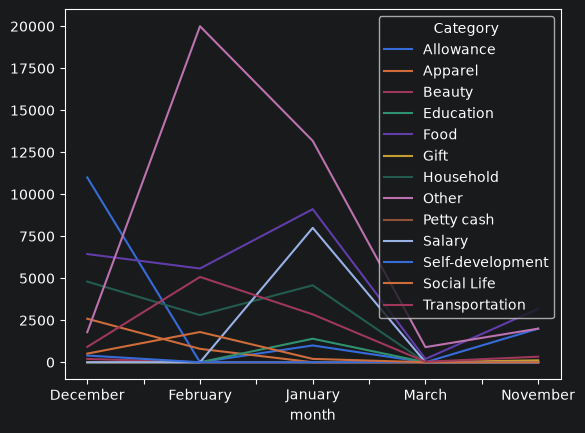

In [9]:
df.pivot_table(index='month',columns='Category',values='INR',aggfunc='sum',fill_value=0).plot()

<Axes: xlabel='month'>

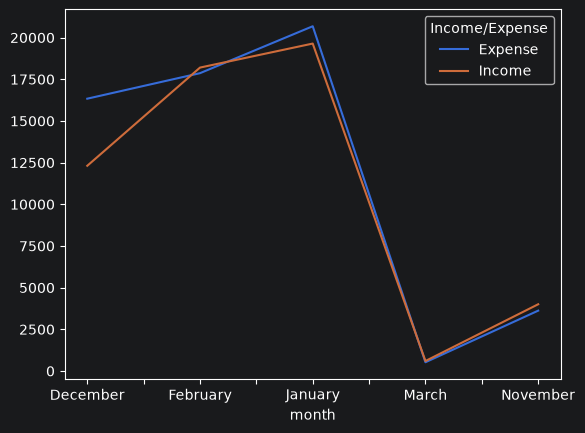

In [10]:
df.pivot_table(index='month',columns='Income/Expense',values='INR',aggfunc='sum',fill_value=0).plot()

<Axes: xlabel='month'>

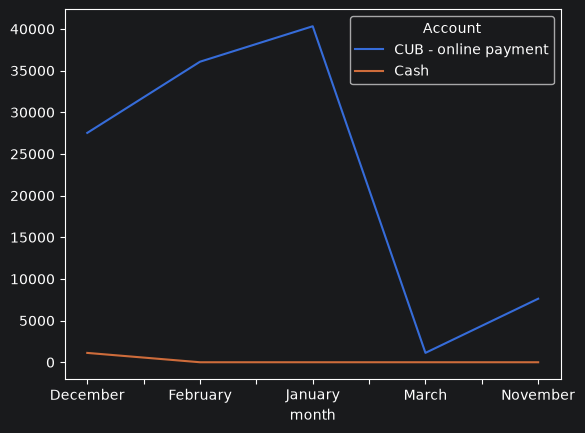

In [11]:
df.pivot_table(index='month',columns='Account',values='INR',aggfunc='sum',fill_value=0).plot()